# Avaliação do RAG — Agente para o Estudante (ASA Turbo)

Mede se o chat **encontra o documento certo**, **se abstém quando não sabe** e **só afirma o que está nas fontes**.

- **Corpus:** os 20 documentos fictícios da Entrega 1 (`src/Entrega 1/seed_v2.sql`), 1 trecho cada.
- **Perguntas:** `ml/rag_eval/perguntas.jsonl`, 60 no total: 20 diretas, 20 reformuladas (vocabulário do estudante, sem as palavras do documento), 8 de continuação (dependem da pergunta anterior) e 12 fora do escopo (6 próximas do domínio, que a base não cobre, e 6 sem relação).
- **Métodos:** TF-IDF por hashing (E1, sem IDF), TF-IDF com tabela IDF (E1), MiniLM-L6 (`all-MiniLM-L6-v2`, pedido na especificação), MiniLM-L12 multilíngue e **bge-m3**, o modelo que roda em produção via Cloudflare, aqui executado localmente com os mesmos pesos.
- **Recuperação:** `ml/rag/recuperacao.py` reproduz em memória a RPC `buscar_chunks_similares` e o `processar_pergunta` de `web/api/perguntar.py` (o `backend/app/rag/` ainda não existe). Continuações usam a última pergunta do estudante concatenada à atual.

In [1]:
import os, sys, json, logging
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TRANSFORMERS_VERBOSITY"] = "error"
logging.disable(logging.WARNING)   # sem avisos do Hugging Face nas saídas
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ML = Path.cwd() if (Path.cwd() / "avaliar_rag.py").exists() else Path.cwd() / "ml"
sys.path.insert(0, str(ML))
import warnings; warnings.filterwarnings("ignore")
import avaliar_rag as ar
EVID = ML.parent / "docs" / "evidencias"
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)
perguntas = ar.carregar_perguntas()
display(pd.Series([p["tipo"] for p in perguntas]).value_counts().rename("perguntas").to_frame())
display(pd.DataFrame([{k: p[k] for k in ("id", "tipo", "contexto", "pergunta", "rotulos_esperados")} for p in perguntas[1::8]]))

,perguntas
direta,20
reformulada,20
continuacao,8
fora_escopo_proxima,6
fora_escopo,6


,id,tipo,contexto,pergunta,rotulos_esperados
0,q02,reformulada,[],"Tô devendo uma parcela, consigo renovar meu vínculo pro próximo semestre?",[rematricula]
1,q10,reformulada,[],"Se eu faltar muito numa matéria mas tirar nota boa, ainda passo?",[freq]
2,q18,reformulada,[],"Já fiz essa matéria na outra universidade, preciso cursar de novo?",[aproveitamento]
3,q26,reformulada,[],Até quando preciso escolher quem vai me orientar na monografia?,[tcc]
4,q34,reformulada,[],"Consegui emprego de manhã, dá pra passar a estudar à noite?","[turno, transferencia]"
5,q42,continuacao,[Perdi a prova de cálculo porque fiquei doente],Até quando posso pedir?,"[segunda, atestado]"
6,q50,fora_escopo_proxima,[],Como peço vaga no estacionamento da faculdade?,[]
7,q58,fora_escopo,[],Me recomenda uma série para assistir hoje,[]


## 1. Rodar a avaliação (≈20 s; os modelos ficam em cache local)

,Recall@1,Recall@3,MRR
"TF-IDF (hashing, sem IDF)",0.729,0.938,0.833
TF-IDF + tabela IDF,0.729,0.917,0.837
MiniLM-L6 (all-MiniLM-L6-v2),0.521,0.688,0.625
MiniLM-L12 multilíngue,0.708,0.854,0.800
bge-m3 (modelo de produção),0.938,0.958,0.951


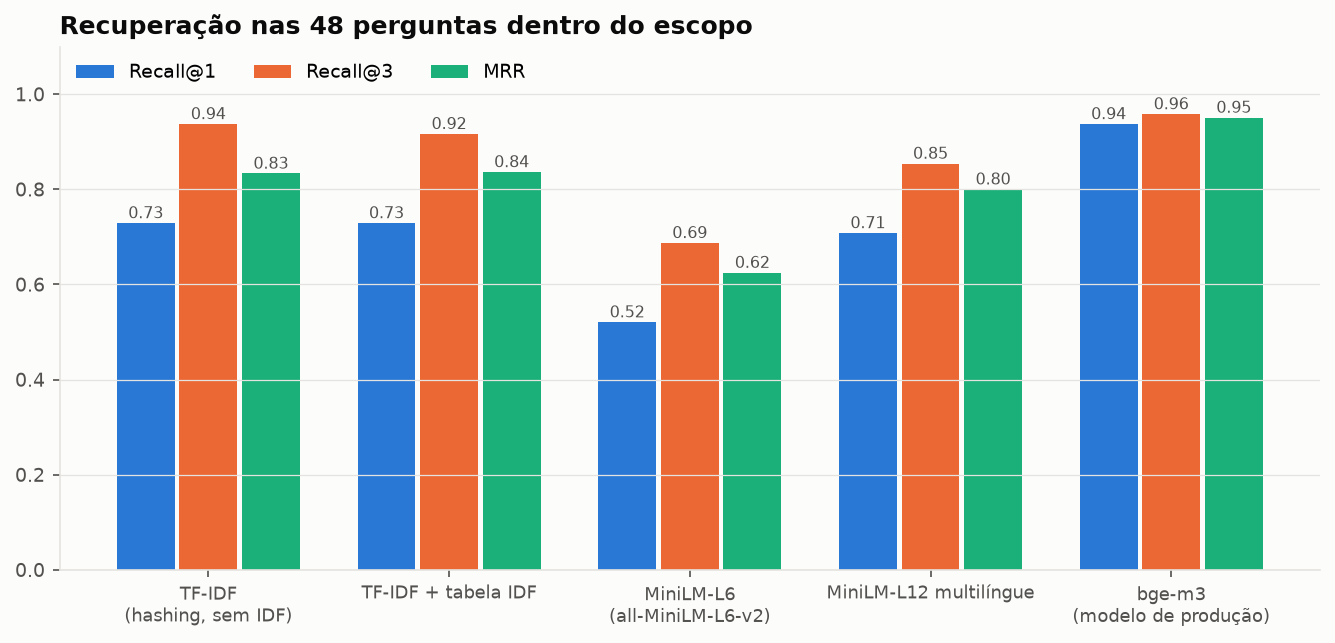

In [2]:
S = ar.executar(verbose=False)
M = S["metodos"]
tab = pd.DataFrame({v["nome"]: {"Recall@1": v["recuperacao"]["dentro_do_escopo"]["recall_at_1"], "Recall@3": v["recuperacao"]["dentro_do_escopo"]["recall_at_3"],
                                "MRR": v["recuperacao"]["dentro_do_escopo"]["mrr"]} for v in M.values()}).T
display(tab)
display(Image(EVID / "rag_recuperacao.png", width=720))

**Leitura:** o **bge-m3** encontra o documento certo em primeiro lugar em ~94% das perguntas (MRR 0,95). Os TF-IDF da E1 ficam em ~73% e o MiniLM-L6 é o pior (52%): é um modelo **treinado em inglês**, aplicado a uma base em português. A versão multilíngue do MiniLM melhora (71%), mas não alcança o bge-m3. Isso confirma, com números, a decisão da Fase 0 de migrar para o bge-m3.

In [3]:
por_tipo = pd.DataFrame({v["nome"]: {t: v["recuperacao"]["por_tipo"][t]["recall_at_1"] for t in ("direta", "reformulada", "continuacao")} for v in M.values()}).T
por_tipo["continuação SEM contexto"] = [v["continuacao_sem_contexto_recall_at_1"] for v in M.values()]
print("Recall@1 por tipo de pergunta"); display(por_tipo)

Recall@1 por tipo de pergunta


,direta,reformulada,continuacao,continuação SEM contexto
"TF-IDF (hashing, sem IDF)",0.90,0.55,0.750,0.375
TF-IDF + tabela IDF,0.85,0.55,0.875,0.375
MiniLM-L6 (all-MiniLM-L6-v2),0.85,0.20,0.500,0.250
MiniLM-L12 multilíngue,0.90,0.50,0.750,0.250
bge-m3 (modelo de produção),1.00,0.85,1.000,0.625


**Leitura:**
- **Diretas** são fáceis para todos (≥ 85%), porque repetem as palavras do documento.
- **Reformuladas** separam os métodos: o TF-IDF cai para ~55% e o MiniLM-L6 para 20%, enquanto o bge-m3 mantém 85%. Estudante não escreve como o regulamento ("tô devendo uma parcela" × "pendências financeiras"); é aqui que o modelo semântico paga o custo.
- **Continuações** ("E por quanto tempo?") sem contexto acertam no máximo 62%; com a pergunta anterior na consulta, o bge-m3 acerta todas. O backend precisa mandar ao menos a última mensagem do estudante junto com a pergunta.

## 2. Abstenção e escolha do limiar

,dentro_media,dentro_min,fora_media,fora_max
"TF-IDF (hashing, sem IDF)",0.320,0.098,0.178,0.348
TF-IDF + tabela IDF,0.267,0.101,0.134,0.256
MiniLM-L6 (all-MiniLM-L6-v2),0.586,0.482,0.509,0.592
MiniLM-L12 multilíngue,0.534,0.266,0.299,0.643
bge-m3 (modelo de produção),0.665,0.466,0.422,0.547


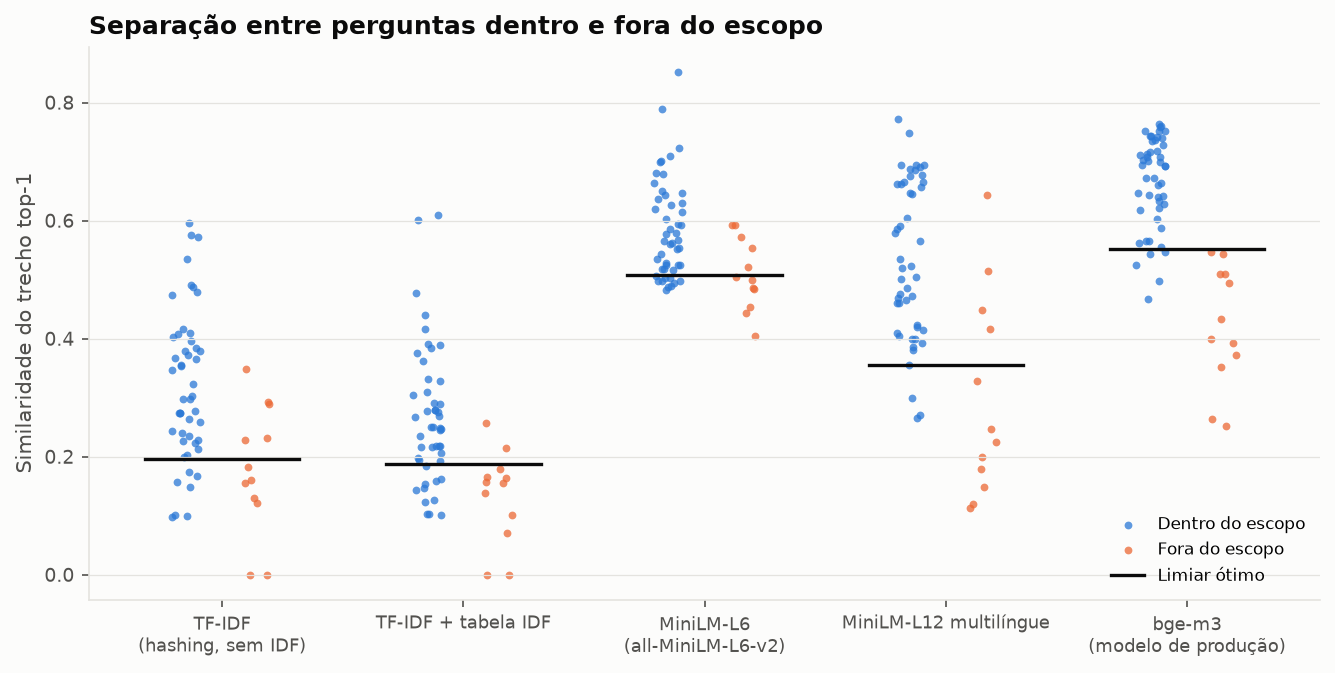

In [4]:
sim = pd.DataFrame({v["nome"]: v["similaridade_top1"] for v in M.values()}).T
display(sim)
display(Image(EVID / "rag_similaridades.png", width=720))

**Leitura:** para cada método, o que importa é a **folga** entre a similaridade das perguntas dentro e fora do escopo. No MiniLM-L6 as duas nuvens se sobrepõem quase inteiras (tudo fica entre 0,45 e 0,85): nenhum limiar separa bem. No bge-m3 todas as perguntas fora do escopo ficam abaixo de 0,55 (máximo 0,547), e a grande maioria das de dentro fica acima (média 0,66).

,limiar,abstencao_correta,abstencao_indevida,precisao_das_respostas,respostas_erradas,acerto_do_agente,acerto (CV),limiar (CV) média ± dp
"TF-IDF (hashing, sem IDF)",0.197,0.583,0.146,0.674,15,0.633,0.583,0.171 ± 0.023
TF-IDF + tabela IDF,0.187,0.833,0.229,0.795,8,0.683,0.633,0.181 ± 0.011
MiniLM-L6 (all-MiniLM-L6-v2),0.508,0.583,0.208,0.581,18,0.533,0.533,0.508 ± 0.001
MiniLM-L12 multilíngue,0.355,0.667,0.083,0.708,14,0.7,0.65,0.366 ± 0.047
bge-m3 (modelo de produção),0.551,1.0,0.104,0.977,1,0.9,0.867,0.544 ± 0.014


bge-m3 no limiar de produção (0,55): {'limiar': 0.55, 'abstencao_correta': 1.0, 'abstencao_indevida': 0.1042, 'precisao_das_respostas': 0.9767, 'respostas_erradas': 1, 'acerto_do_agente': 0.9}


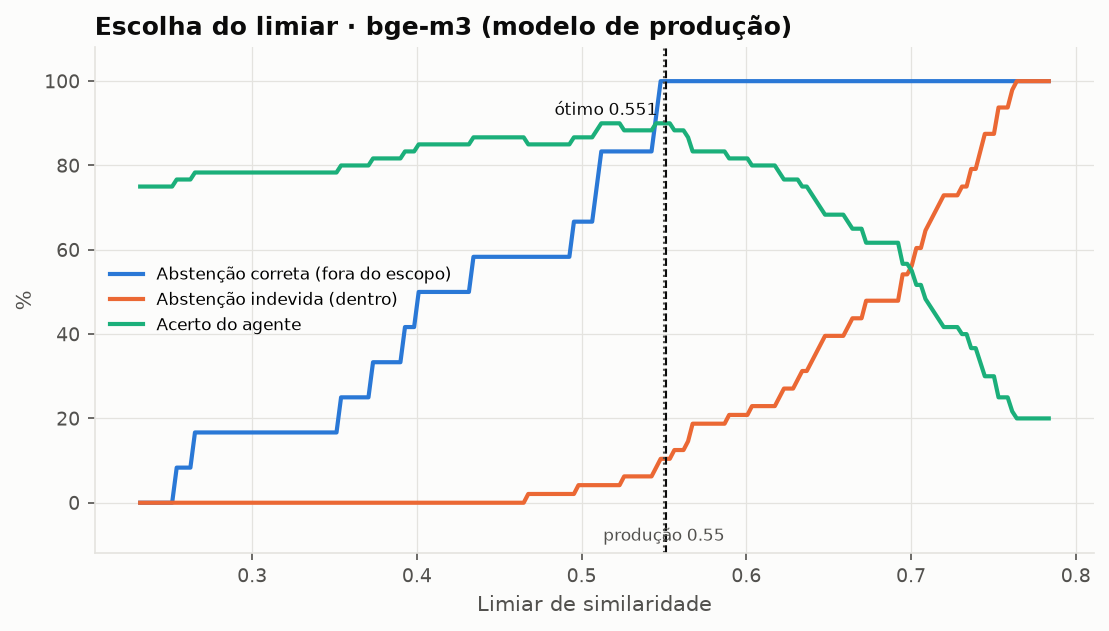

In [5]:
dec = pd.DataFrame({v["nome"]: {**v["no_limiar_otimo"], "acerto (CV)": v["validacao_cruzada_limiar"]["acerto_cv"],
                                "limiar (CV) média ± dp": f"{v['validacao_cruzada_limiar']['limiar_medio']:.3f} ± {v['validacao_cruzada_limiar']['limiar_dp']:.3f}"}
                    for v in M.values()}).T
display(dec[["limiar", "abstencao_correta", "abstencao_indevida", "precisao_das_respostas", "respostas_erradas", "acerto_do_agente", "acerto (CV)", "limiar (CV) média ± dp"]])
print("bge-m3 no limiar de produção (0,55):", M["bge_m3"]["no_limiar_producao_0_55"])
display(Image(EVID / "rag_limiar.png", width=620))

**Como o limiar foi escolhido:** para cada método, o limiar que maximiza o **acerto do agente** (pergunta de dentro respondida com o documento certo + pergunta de fora com abstenção). Quando vários limiares empatam, fica o intervalo de maior limiar (mais conservador). Como o limiar é escolhido nas mesmas 60 perguntas, a coluna **acerto (CV)** dá a estimativa honesta: limiar escolhido em 4/5 das perguntas e medido no 1/5 restante.

**Leitura:**
- **bge-m3, limiar ótimo ≈ 0,55**, o mesmo que já está em produção (`CONFIDENCE_THRESHOLD = 0.55`, calibrado em outubro com outra amostra). Nele: **100% de abstenção correta** (as 12 fora do escopo, inclusive "senha do portal" e "estacionamento"), **~10% de abstenção indevida** (5 de 48 perguntas de dentro vão para o atendente humano), precisão das respostas de ~98% e só **1 resposta errada** em 60. A estimativa por CV (~87%) fica perto do valor no conjunto todo (90%), e o limiar varia pouco entre as dobras (±0,014).
- Os demais métodos não chegam perto: o melhor deles (MiniLM multilíngue) erra ou se abstém indevidamente em ~1/3 das perguntas.
- **Recomendação:** manter **bge-m3 com limiar 0,55**. Abstenção indevida custa um encaminhamento a um humano; resposta errada custa um aluno mal orientado, então o custo assimétrico favorece o lado conservador.

In [6]:
r = {x["id"]: x for x in ar.rodar(__import__("rag.recuperacao", fromlist=["x"]).Recuperador(ar.METODOS["bge_m3"][1](), ar.carregar_corpus()), perguntas)}
ab = [{"id": p["id"], "tipo": p["tipo"], "pergunta": p["pergunta"], "similaridade": round(r[p["id"]]["sim_top1"], 3), "top1_correto": r[p["id"]]["top1_correto"]}
      for p in perguntas if p["tipo"] in ar.DENTRO and r[p["id"]]["sim_top1"] < 0.55]
print("Perguntas de dentro do escopo encaminhadas ao humano no limiar 0,55 (bge-m3):"); display(pd.DataFrame(ab))

Perguntas de dentro do escopo encaminhadas ao humano no limiar 0,55 (bge-m3):


,id,tipo,pergunta,similaridade,top1_correto
0,q04,reformulada,"Preciso de um papel que comprove que estudo aí pro meu estágio, onde consigo?",0.544,False
1,q20,reformulada,"Quero sair de Administração e ir para Economia, é possível?",0.497,False
2,q26,reformulada,Até quando preciso escolher quem vai me orientar na monografia?,0.466,True
3,q30,reformulada,Tem alguém que revise meu currículo e me prepare para entrevista?,0.524,True
4,q40,reformulada,"Perdi meu emprego e não consigo pagar a faculdade, existe alguma ajuda?",0.547,True


**Leitura:** as 5 abstenções indevidas são todas **reformuladas**, coloquiais e indiretas ("papel que comprove que estudo", "sair de Administração e ir para Economia", "perdi meu emprego..."), com similaridade logo abaixo do limiar (0,47–0,55). Em 2 delas o documento top-1 nem é o certo, e o encaminhamento ao humano evita uma resposta errada. Nas outras 3 o agente acertaria. Esse é o custo aceito de um limiar conservador.

## 3. Groundedness

A resposta atual do agente é **extrativa**: o texto do trecho top-1, sem reescrita. Por construção, ela só afirma o que está na fonte. O risco real é outro: **responder com o trecho fundamentado de um documento que não é o da pergunta**.

O verificador (`ml/rag/groundedness.py`) checa cada frase da resposta contra os trechos recuperados: todo **número** (prazo, quantidade, percentual) precisa aparecer nos trechos, e ≥ 70% dos termos de conteúdo também. Ele foi validado com respostas **adulteradas**, para já servir quando o backend passar a compor respostas (passo a passo, resumo).

In [7]:
display(pd.Series(S["groundedness"]).to_frame("bge-m3 no limiar escolhido"))
display(pd.Series(S["validacao_verificador_groundedness"]).to_frame("validação do verificador"))

,bge-m3 no limiar escolhido
respostas_avaliadas,43
groundedness_media,1.0
respostas_100pct_fundamentadas,1.0
fundamentadas_mas_documento_errado,1
metodo,bge_m3
observacao,"a resposta atual é extrativa (trecho top-1), por isso é sempre fundamentada; o risco r..."


,validação do verificador
respostas_fieis_aceitas,1.0
n_fieis,40.0
numero_trocado_detectado,1.0
n_numero,15.0
frase_inventada_detectada,1.0
n_inventada,20.0


In [8]:
from rag.groundedness import verificar
trecho = ar.carregar_corpus()[2].conteudo
exemplos = {"fiel": trecho, "prazo trocado": ar._trocar_numero(trecho), "frase inventada": trecho + " " + ar.INVENTADAS[0]}
for nome, resp in exemplos.items():
    v = verificar(resp, [trecho])
    print(f"[{nome}] fundamentada={v['fundamentada']} score={v['score']}")
    for f in v["frases"]:
        if not f["suportada"]:
            print("   sem suporte:", f["frase"], "| números sem suporte:", f["numeros_sem_suporte"], "| cobertura:", f["cobertura"])

[fiel] fundamentada=True score=1.0
[prazo trocado] fundamentada=False score=0.0
   sem suporte: O trancamento de matrícula deve ser solicitado com 22 dias de antecedência do início do semestre e pode impactar bolsas ou financiamentos ativos. | números sem suporte: ['22'] | cobertura: 1.0
[frase inventada] fundamentada=False score=0.5
   sem suporte: Além disso, o pedido também pode ser feito pelo WhatsApp da coordenação. | números sem suporte: [] | cobertura: 0.0


**Leitura:**
- **Groundedness das respostas = 100%**: todas as 43 respostas dadas pelo bge-m3 no limiar escolhido estão integralmente nos trechos recuperados (esperado, já que a resposta é extrativa).
- **O verificador funciona**: aceita 100% das respostas fiéis (inteiras ou resumidas em uma frase) e pega **100% dos prazos trocados** (15 casos) e **100% das frases inventadas** (20 casos). É uma checagem simples, sem LLM, que pode rodar em cada resposta antes de enviar.
- **1 resposta fundamentada, mas no documento errado** (q02, abaixo). É o tipo de erro que groundedness não detecta, e por isso a precisão de recuperação é a métrica principal.

## 4. Revisão manual de amostra

In [9]:
rev = [json.loads(l) for l in (ML / "rag_eval" / "revisao_amostra.jsonl").read_text(encoding="utf-8").splitlines()]
display(pd.DataFrame([{"id": x["id"], "tipo": x["tipo"], "pergunta": x["pergunta"], "documento": x["documento_recuperado"],
                       "responde": x["revisao_humana"]["responde_a_pergunta"], "fundamentada": x["revisao_humana"]["fundamentada"],
                       "comentário": x["revisao_humana"]["comentario"]} for x in rev]))
print(S["revisao_amostra"])

,id,tipo,pergunta,documento,responde,fundamentada,comentário
0,q02,reformulada,"Tô devendo uma parcela, consigo renovar meu vínculo pro próximo semestre?",Bolsas e Financiamentos,False,True,Trecho de renovação de bolsa/FIES. A pergunta é sobre rematrícula com parcela em abert...
1,q03,direta,Como emito a declaração de matrícula?,Declaração de Matrícula,True,True,Responde onde e como emitir.
2,q05,direta,Qual o prazo para pedir o trancamento de matrícula?,Trancamento de Matrícula,True,True,Prazo de 15 dias citado.
3,q10,reformulada,"Se eu faltar muito numa matéria mas tirar nota boa, ainda passo?",Reprovação por Frequência,True,True,Responde diretamente: reprova por frequência independente da nota.
4,q17,direta,Como funciona o aproveitamento de disciplinas cursadas em outra faculdade?,Aproveitamento de Disciplinas,True,True,Explica onde pedir e o critério de 75%.
5,q25,direta,Quando devo começar o TCC?,Trabalho de Conclusão de Curso (TCC),True,True,"Penúltimo semestre, como perguntado."
6,q29,direta,O ASA ajuda com carreira e vagas de emprego?,Carreira e Empregabilidade (ASA),True,True,Lista os serviços de carreira.
7,q32,reformulada,"Fiquei doente e perdi aula, como faço pra não levar falta?",Atestado Médico e Justificativa de Falta,True,True,Atestado em até 48 h pelo portal.
8,q36,reformulada,"Já colei grau, quando recebo o comprovante de conclusão?",Certificado e Diploma,True,True,Certificado em até 30 dias após a colação.
9,q41,continuacao,E isso afeta minha bolsa?,Trancamento de Matrícula,True,True,Continuação resolvida pelo contexto. O trecho só diz que 'pode impactar' bolsas; é o q...


{'arquivo': 'ml/rag_eval/revisao_amostra.jsonl', 'n': 13, 'revisadas': 13, 'responde_a_pergunta': 0.9231, 'fundamentada': 1.0, 'revisor': 'sessão de IA (Claude), 02/11/2026 — pendente de confirmação por um membro da equipe'}


**Leitura:** 13 respostas revisadas (12 sorteadas + a única resposta com documento errado): 12 respondem à pergunta, todas são fundamentadas. A falha (q02) mostra o caso de maior risco para o estudante: perguntou se pode se rematricular devendo uma parcela e recebeu o trecho de renovação de bolsa, que não diz nada sobre pendência. A revisão foi feita por esta sessão de IA e está marcada no arquivo como **pendente de confirmação por um membro da equipe**.

## 5. Conclusão

| | bge-m3 (produção) | melhor alternativa |
|---|---|---|
| Recall@1 / Recall@3 / MRR | ~0,94 / ~0,96 / ~0,95 | TF-IDF + IDF: ~0,73 / ~0,92 / ~0,84 |
| Limiar ótimo | **0,55** (= produção) | — |
| Abstenção correta / indevida | 100% / ~10% | MiniLM multilíngue: ~67% / ~8% |
| Acerto do agente (CV) | ~0,87 | ~0,65 |
| Groundedness | 100% (extrativa); verificador pega 100% das adulterações | — |

**Recomendações para o backend:**
1. Manter **bge-m3** e **limiar 0,55**.
2. Enviar a **última mensagem do estudante** junto com a pergunta: sem isso, continuações caem de 100% para ~62%.
3. Se a resposta passar a ser composta (resumo, passo a passo), rodar `rag.groundedness.verificar` antes de enviar e se abster quando houver número sem suporte.
4. Repetir esta avaliação na **base real** (230 documentos, `seeds/base_conhecimento_oficial.sql`) com perguntas reais vindas de `feedback_respostas`. O corpus fictício tem 1 trecho por documento e é mais fácil que a base real.